# Interpretation of three selected tree models

Scope: four-class XGBoost, binary LightGBM, and binary Random Forest from
`hao_models.ipynb`, upstream commit `bdb51d3b6fa87fc6688586e16917feb995f4addb`.
The original `data7703.ipynb` fits are a separate experiment and must not be substituted silently.

This notebook reads the group's prepared data and model state. It writes only to a new
`tree_interpretability_results` directory. It does not edit the group notebooks or caches.
The completed analysis outputs are retained. The two environment/path setup cells were adjusted for portability after execution, and their outputs were cleared. Model-analysis cells retain the original results.

The upstream notebook removes the XGBoost and Random Forest model objects after evaluation.
If those objects are absent, predictions alone cannot support new feature explanations.
Optional refitting below reproduces their specified settings in this separate directory;
it is recorded as a new fit, with a check against the cached validation probabilities.

## Select a compatible Python environment

Use a Python environment with the versions in `requirements.txt`. The environment check below
is portable and does not require a machine-specific kernel registration.


In [ ]:
# Check the model-library versions before loading saved estimators.
from importlib.metadata import version, PackageNotFoundError

for package, expected in {'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'xgboost': '3.4.1'}.items():
    try:
        actual = version(package)
    except PackageNotFoundError as error:
        raise RuntimeError('Select the model environment and install requirements.txt before running.') from error
    if actual != expected:
        raise RuntimeError(f'{package}: expected {expected}, got {actual}. Select the matched model environment.')
print('Environment check passed.')


## 1. Environment and paths

The actual run used Python 3.14.3 and the versions in `requirements.txt`. The group cache was
produced with Python 3.12.14; its selected LightGBM predictions were checked in the actual run.
This notebook uses exact grouped empirical interventional Shapley values and does not require
the SHAP package.

Open the notebook from the repository root, `contributions/terrygao03-cell`, or this analysis
folder. Set `GROUP_MODEL_PROJECT` (or edit `PROJECT_DIR`) to the directory containing the group's
`data/prepared.joblib` and `data/experiment.joblib` when they are stored elsewhere.
The alternate filename `prepared(1).joblib` is also accepted.

The saved analysis outputs can be reviewed without rerunning. To recompute, use the input
caches from the teammate who ran `hao_models.ipynb`. That cache may lack XGBoost/RandomForest
fitted objects. `ALLOW_REFIT_MISSING=False` stops before missing objects are reproduced;
set it to `True` to independently refit those two models with the original settings.
The already selected LightGBM model is reused. Refits are saved only in this contribution.


In [ ]:
import gc
import json
import math
import os
import platform
from importlib.metadata import version, PackageNotFoundError
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import f1_score, accuracy_score
from sklearn.model_selection import train_test_split

analysis_candidates = [Path.cwd(), Path.cwd() / 'tree_model_interpretability',
                       Path.cwd() / 'contributions' / 'terrygao03-cell' / 'tree_model_interpretability']
ANALYSIS_DIR = next((path.resolve() for path in analysis_candidates
                     if (path / 'tree_model_interpretability.ipynb').is_file()), None)
if ANALYSIS_DIR is None:
    raise FileNotFoundError('Run from the repository root, the personal contribution folder, or this notebook folder.')
project_candidates = [ANALYSIS_DIR, *ANALYSIS_DIR.parents]
detected_project = next((path for path in project_candidates
                         if (path / 'data' / 'experiment.joblib').is_file()), ANALYSIS_DIR)
PROJECT_DIR = Path(os.environ.get('GROUP_MODEL_PROJECT', str(detected_project))).expanduser().resolve()
prepared_candidates = [PROJECT_DIR / 'data' / 'prepared.joblib', PROJECT_DIR / 'data' / 'prepared(1).joblib']
PREPARED_PATH = next((path for path in prepared_candidates if path.is_file()), prepared_candidates[0])
STATE_PATH = PROJECT_DIR / 'data' / 'experiment.joblib'
OUTPUT_DIR = ANALYSIS_DIR / 'tree_interpretability_results'
ALLOW_REFIT_MISSING = False
GLOBAL_ROWS = 6000
CASE_POOL_ROWS = 10000
PERMUTATION_REPEATS = 5
BACKGROUND_ROWS = 64
SEED = 42

LABELS = {
    'four_class': ['Benign', 'Likely_benign', 'Likely_pathogenic', 'Pathogenic'],
    'binary': ['Benign group', 'Pathogenic group'],
}
SELECTED = [('XGBoost', 'four_class'), ('LightGBM', 'binary'), ('RandomForest', 'binary')]
print('Group project:', PROJECT_DIR)
print('New output directory:', OUTPUT_DIR)
environment = {'python': platform.python_version()}
for package in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'lightgbm', 'joblib', 'matplotlib']:
    try:
        environment[package] = version(package)
    except PackageNotFoundError:
        environment[package] = 'not installed'
display(pd.Series(environment, name='Version').to_frame())

In [4]:
missing_inputs = [str(path) for path in [PREPARED_PATH, STATE_PATH] if not path.is_file()]
if missing_inputs:
    raise FileNotFoundError(
        'The group model inputs are missing. Obtain the two caches and set PROJECT_DIR. '
        'GitHub figures and prediction tables are insufficient. Missing: ' + ', '.join(missing_inputs)
    )
prepared = joblib.load(PREPARED_PATH)
state = joblib.load(STATE_PATH)
assert state['source_sha256'] == prepared['source_sha256'], 'Dataset fingerprints differ.'
assert state['design'] == 'group-jupyter-v1', 'Unexpected experiment design.'
X = np.asarray(prepared['X'], dtype=np.float32)
names = list(prepared['feature_names'])
splits = prepared['splits']
targets = prepared['y']
assert X.shape[1] == len(names) and np.isfinite(X).all()
all_rows = np.concatenate([splits[k] for k in ['train', 'calibration', 'validation', 'test']])
assert len(all_rows) == len(X) and len(np.unique(all_rows)) == len(X)
assert all(len(targets[task]) == len(X) for task in LABELS)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'isolated_models').mkdir(exist_ok=True)
display(pd.Series({k: len(v) for k, v in splits.items()}, name='Rows').to_frame())

,Rows
train,944604
calibration,118075
validation,118076
test,506039


## 2. Reuse models or reproduce missing fits

The explained output is the complete sigmoid-calibrated probability, matching the group
evaluation pipeline. A base tree's raw margin or split-count importance does not explain
that same output. Any refit uses only training rows and separate calibration rows.
The first 2,000 validation predictions are compared with the group's cached predictions;
differences are reported, never presented as an identical original fit.

In [5]:
def feature_input(values, as_frame):
    return pd.DataFrame(values, columns=names) if as_frame else values

def probabilities(item, values, task):
    expected_classes = np.arange(len(LABELS[task]))
    assert np.array_equal(item['model'].classes_, expected_classes)
    result = np.asarray(item['model'].predict_proba(feature_input(values, item['as_frame'])), dtype=float)
    assert result.shape == (len(values), len(expected_classes))
    assert np.isfinite(result).all() and (result >= 0).all()
    assert np.allclose(result.sum(axis=1), 1, atol=1e-5)
    return result

def reproduce_missing(name, task):
    from sklearn.calibration import CalibratedClassifierCV
    from sklearn.frozen import FrozenEstimator
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.utils.class_weight import compute_sample_weight

    if name == 'XGBoost' and task == 'four_class':
        from xgboost import XGBClassifier
        base = XGBClassifier(n_estimators=100, random_state=42, n_jobs=2)
        weights = compute_sample_weight('balanced', targets[task][splits['train']])
        base.fit(X[splits['train']], targets[task][splits['train']], sample_weight=weights)
    elif name == 'RandomForest' and task == 'binary':
        base = RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample',
                                      random_state=42, n_jobs=2)
        base.fit(X[splits['train']], targets[task][splits['train']])
    else:
        raise RuntimeError('The selected LightGBM fit must be supplied in experiment.joblib.')
    model = CalibratedClassifierCV(FrozenEstimator(base), method='sigmoid')
    model.fit(X[splits['calibration']], targets[task][splits['calibration']])
    return dict(model=model, as_frame=False, provenance='independent refit with upstream settings',
                source_sha256=prepared['source_sha256'], environment=environment)

missing_models = [(name, task) for name, task in SELECTED
                  if 'model' not in state['models'][name][task]
                  and not (OUTPUT_DIR / 'isolated_models' / f'{name}_{task}.joblib').is_file()]
print('Models absent from saved state:', missing_models)
if missing_models and not ALLOW_REFIT_MISSING:
    raise RuntimeError(
        'Missing fitted objects. Ask for the retained calibrated model objects, or set '
        'ALLOW_REFIT_MISSING=True to reproduce only the missing XGBoost/RandomForest fits. '
        'The original group files will not be changed.'
    )

selected_models, model_checks = {}, []
for name, task in SELECTED:
    original = state['models'][name][task]
    saved_path = OUTPUT_DIR / 'isolated_models' / f'{name}_{task}.joblib'
    if 'model' in original:
        item = dict(model=original['model'], as_frame=original.get('as_frame', False),
                    provenance='loaded original calibrated model', source_sha256=prepared['source_sha256'])
    elif saved_path.is_file():
        item = joblib.load(saved_path)
        assert item['source_sha256'] == prepared['source_sha256']
    else:
        print('Reproducing:', name, task, flush=True)
        item = reproduce_missing(name, task)
        joblib.dump(item, saved_path, compress=3)
        gc.collect()
    count = min(2000, len(splits['validation']))
    actual = probabilities(item, X[splits['validation'][:count]], task)
    expected = np.asarray(original['validation'][:count], dtype=float)
    max_difference = float(np.max(np.abs(actual - expected)))
    model_checks.append(dict(model=name, task=task, provenance=item['provenance'],
                             checked_rows=count, max_probability_difference=max_difference,
                             agrees_with_cached_probabilities=bool(np.allclose(actual, expected, atol=1e-5, rtol=1e-5))))
    selected_models[(name, task)] = item
model_checks = pd.DataFrame(model_checks)
model_checks.to_csv(OUTPUT_DIR / 'model_provenance_checks.csv', index=False)
display(model_checks)

Models absent from saved state: [('XGBoost', 'four_class'), ('RandomForest', 'binary')]
Reproducing: XGBoost four_class
Reproducing: RandomForest binary


,model,task,provenance,checked_rows,max_probability_difference,agrees_with_cached_probabilities
0,XGBoost,four_class,independent refit with upstream settings,2000,2.979028e-08,True
1,LightGBM,binary,loaded original calibrated model,2000,2.976706e-08,True
2,RandomForest,binary,independent refit with upstream settings,2000,2.883365e-08,True


## 3. Common feature groups and held-out samples

One-hot columns of a categorical variable are shuffled together. This preserves the
encoding within that group. Binary LightGBM and Random Forest use identical sampled rows,
background rows, and permutations. Four-class and binary score drops are not directly
comparable because their targets differ. Repeated-permutation SD is not a confidence
interval over retraining or new datasets.

In [6]:
groups = {}
for group in ['CHROM', 'POS', 'AF_EXAC', 'AF_TGP', 'AF_ESP', 'CLNVC', 'MC_Clean', 'Primary_Gene_Freq']:
    groups[group] = [i for i, name in enumerate(names) if name == group or
                     (group in ['CHROM', 'CLNVC', 'MC_Clean'] and name.startswith(group + '_'))]
assert all(groups.values()), 'An expected feature group is absent.'
assert sorted(i for columns in groups.values() for i in columns) == list(range(X.shape[1]))

def stratified_rows(rows, limit):
    rows = np.asarray(rows)
    if len(rows) <= limit:
        return rows.copy()
    selected, _ = train_test_split(rows, train_size=limit, random_state=SEED,
                                   stratify=targets['four_class'][rows])
    return np.sort(selected)

global_rows = stratified_rows(splits['validation'], GLOBAL_ROWS)
case_rows = stratified_rows(splits['test'], CASE_POOL_ROWS)
background_rows = stratified_rows(splits['train'], BACKGROUND_ROWS)
background = X[background_rows]
np.savez_compressed(OUTPUT_DIR / 'explanation_row_indices.npz', validation=global_rows,
                    case_pool=case_rows, training_background=background_rows)
(OUTPUT_DIR / 'feature_groups.json').write_text(json.dumps(groups, indent=2), encoding='utf-8')

593

## 4. Global grouped permutation importance

Importance is the decrease in validation macro-F1 after shuffling one feature group.
It measures model reliance on these data, not biological causality or a direction of effect.
Correlated frequency fields can share or conceal importance.

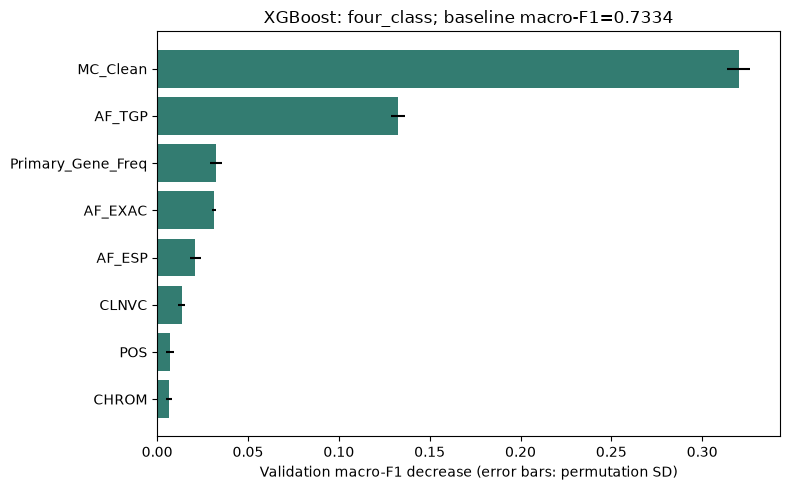

,feature,mean_macro_f1_drop,permutation_sd
6,MC_Clean,0.320110,0.006399
3,AF_TGP,0.132789,0.003890
7,Primary_Gene_Freq,0.032420,0.003250
2,AF_EXAC,0.031287,0.000962
4,AF_ESP,0.021087,0.003239
5,CLNVC,0.013554,0.001800
1,POS,0.006959,0.002054
0,CHROM,0.006764,0.001614


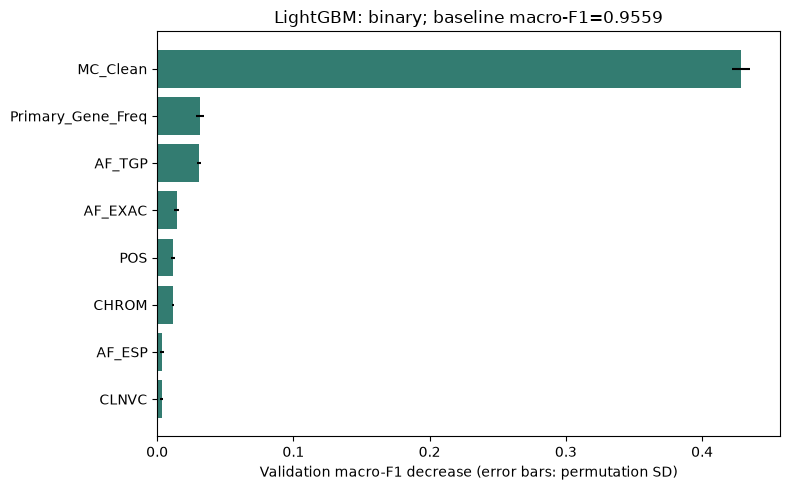

,feature,mean_macro_f1_drop,permutation_sd
6,MC_Clean,0.428540,0.006871
7,Primary_Gene_Freq,0.031679,0.002840
3,AF_TGP,0.030658,0.001171
2,AF_EXAC,0.014269,0.001681
1,POS,0.011518,0.001447
0,CHROM,0.011512,0.000896
4,AF_ESP,0.003537,0.001666
5,CLNVC,0.003362,0.000972


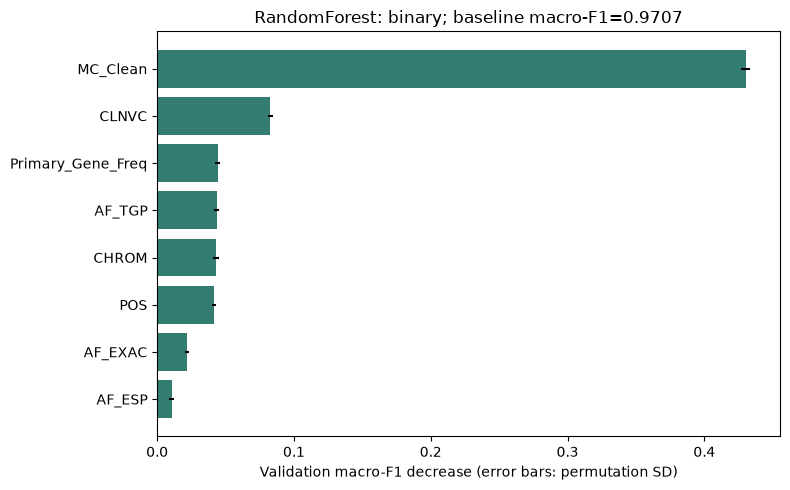

,feature,mean_macro_f1_drop,permutation_sd
6,MC_Clean,0.430175,0.003480
5,CLNVC,0.082664,0.001976
7,Primary_Gene_Freq,0.044169,0.001542
3,AF_TGP,0.043490,0.002063
0,CHROM,0.042935,0.002171
1,POS,0.041503,0.001227
2,AF_EXAC,0.021770,0.001553
4,AF_ESP,0.010536,0.001524


In [7]:
importance_tables = []
for (name, task), item in selected_models.items():
    values = X[global_rows]
    actual = targets[task][global_rows]
    baseline = f1_score(actual, probabilities(item, values, task).argmax(axis=1),
                        average='macro', zero_division=0)
    rng = np.random.default_rng(SEED)
    permutations = [rng.permutation(len(values)) for _ in range(PERMUTATION_REPEATS)]
    records = []
    for group, columns in groups.items():
        drops = []
        for order in permutations:
            shuffled = values.copy()
            shuffled[:, columns] = values[order][:, columns]
            prediction = probabilities(item, shuffled, task).argmax(axis=1)
            drops.append(float(baseline - f1_score(actual, prediction, average='macro', zero_division=0)))
        records.append(dict(model=name, task=task, feature=group, baseline_macro_f1=float(baseline),
                            mean_macro_f1_drop=float(np.mean(drops)),
                            permutation_sd=float(np.std(drops, ddof=1)),
                            **{f'repeat_{i+1}': value for i, value in enumerate(drops)}))
    table = pd.DataFrame(records).sort_values('mean_macro_f1_drop', ascending=False)
    importance_tables.append(table)
    table.to_csv(OUTPUT_DIR / f'{name}_{task}_grouped_importance.csv', index=False)
    plot = table.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(plot['feature'], plot['mean_macro_f1_drop'], xerr=plot['permutation_sd'], color='#337c71')
    ax.axvline(0, color='black', linewidth=.7)
    ax.set(xlabel='Validation macro-F1 decrease (error bars: permutation SD)',
           title=f'{name}: {task}; baseline macro-F1={baseline:.4f}')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'{name}_{task}_global_importance.png', dpi=180)
    plt.show()
    plt.close(fig)
    display(table[['feature', 'mean_macro_f1_drop', 'permutation_sd']])
importance = pd.concat(importance_tables, ignore_index=True)

## 5. Local grouped interventional Shapley explanations

All 256 coalitions of eight feature groups are enumerated against 64 training-background
rows. These are exact Shapley values for this specified grouped empirical masking game,
not Tree SHAP and not estimates of biological causality. Masking between groups can break
real correlations. The complete calibrated class probabilities are explained, so the
baseline probability plus all contributions must reconstruct each predicted probability.

Four cases are selected deterministically from the fixed held-out test pool: a correct
benign-group prediction, a correct pathogenic-group prediction, a false negative, and a
false positive. For four-class correctness, the exact class must also match. If a category
is absent in this pool, it is reported as absent rather than fabricated.

In [8]:
def exact_group_shap(predict, case, reference, feature_groups):
    columns = list(feature_groups.values())
    m = len(columns)
    coalition_count = 1 << m
    masks = np.arange(coalition_count)
    hybrid = np.broadcast_to(reference, (coalition_count, *reference.shape)).copy()
    for j, indices in enumerate(columns):
        included = np.flatnonzero((masks & (1 << j)) != 0)
        for column in indices:
            hybrid[included, :, column] = case[column]
    v = predict(hybrid.reshape(-1, reference.shape[1])).reshape(coalition_count, len(reference), -1).mean(axis=1)
    phi = np.zeros((m, v.shape[1]), dtype=float)
    for j in range(m):
        for mask in masks:
            if not (int(mask) & (1 << j)):
                size = int(mask).bit_count()
                weight = 1.0 / (m * math.comb(m - 1, size))
                phi[j] += weight * (v[int(mask) | (1 << j)] - v[mask])
    observed = predict(case.reshape(1, -1))[0]
    residual = float(np.max(np.abs(v[0] + phi.sum(axis=0) - observed)))
    assert residual < 1e-6, f'Local additivity check failed: {residual}'
    return phi, v[0], observed, residual

def choose_cases(actual, predicted, task):
    positive = actual >= 2 if task == 'four_class' else actual == 1
    predicted_positive = predicted >= 2 if task == 'four_class' else predicted == 1
    conditions = {
        'Correct benign group': (actual == predicted) & ~positive,
        'Correct pathogenic group': (actual == predicted) & positive,
        'False negative': positive & ~predicted_positive,
        'False positive': ~positive & predicted_positive,
    }
    found = []
    for category, condition in conditions.items():
        matching = np.flatnonzero(condition)
        if len(matching):
            found.append((category, int(matching[0])))
        else:
            print('No case in sampled pool:', task, category)
    return found

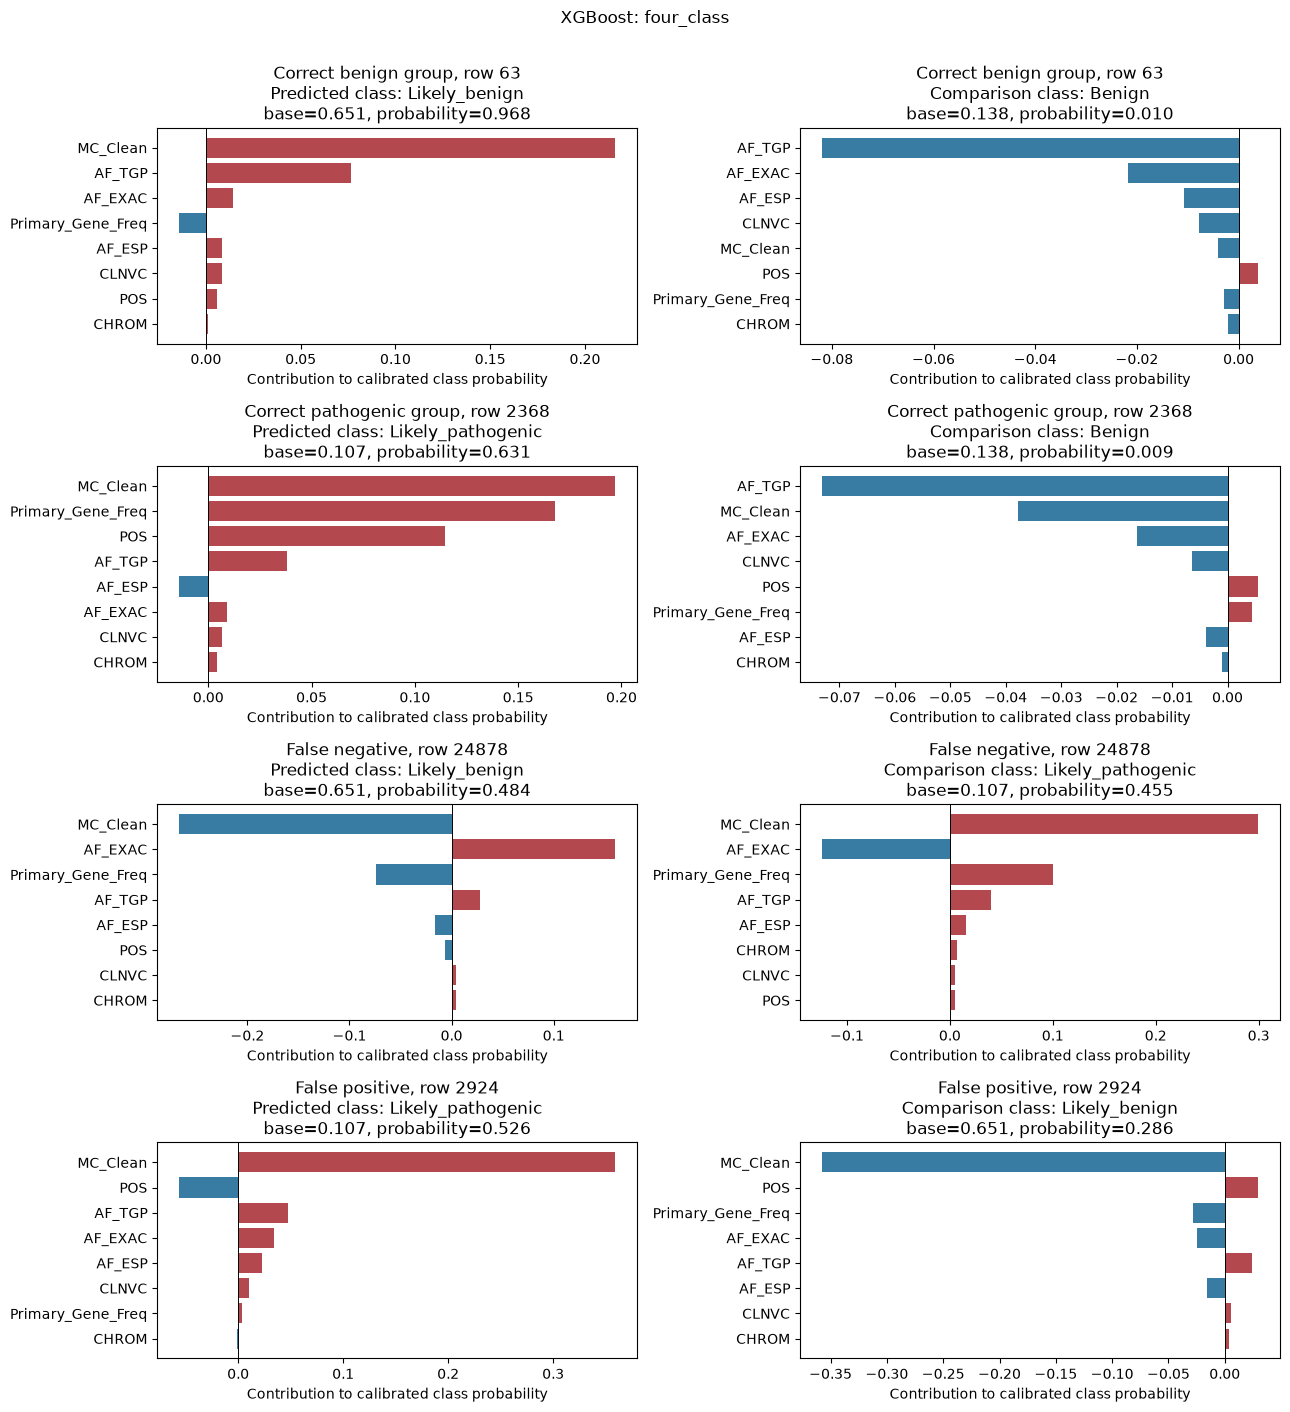

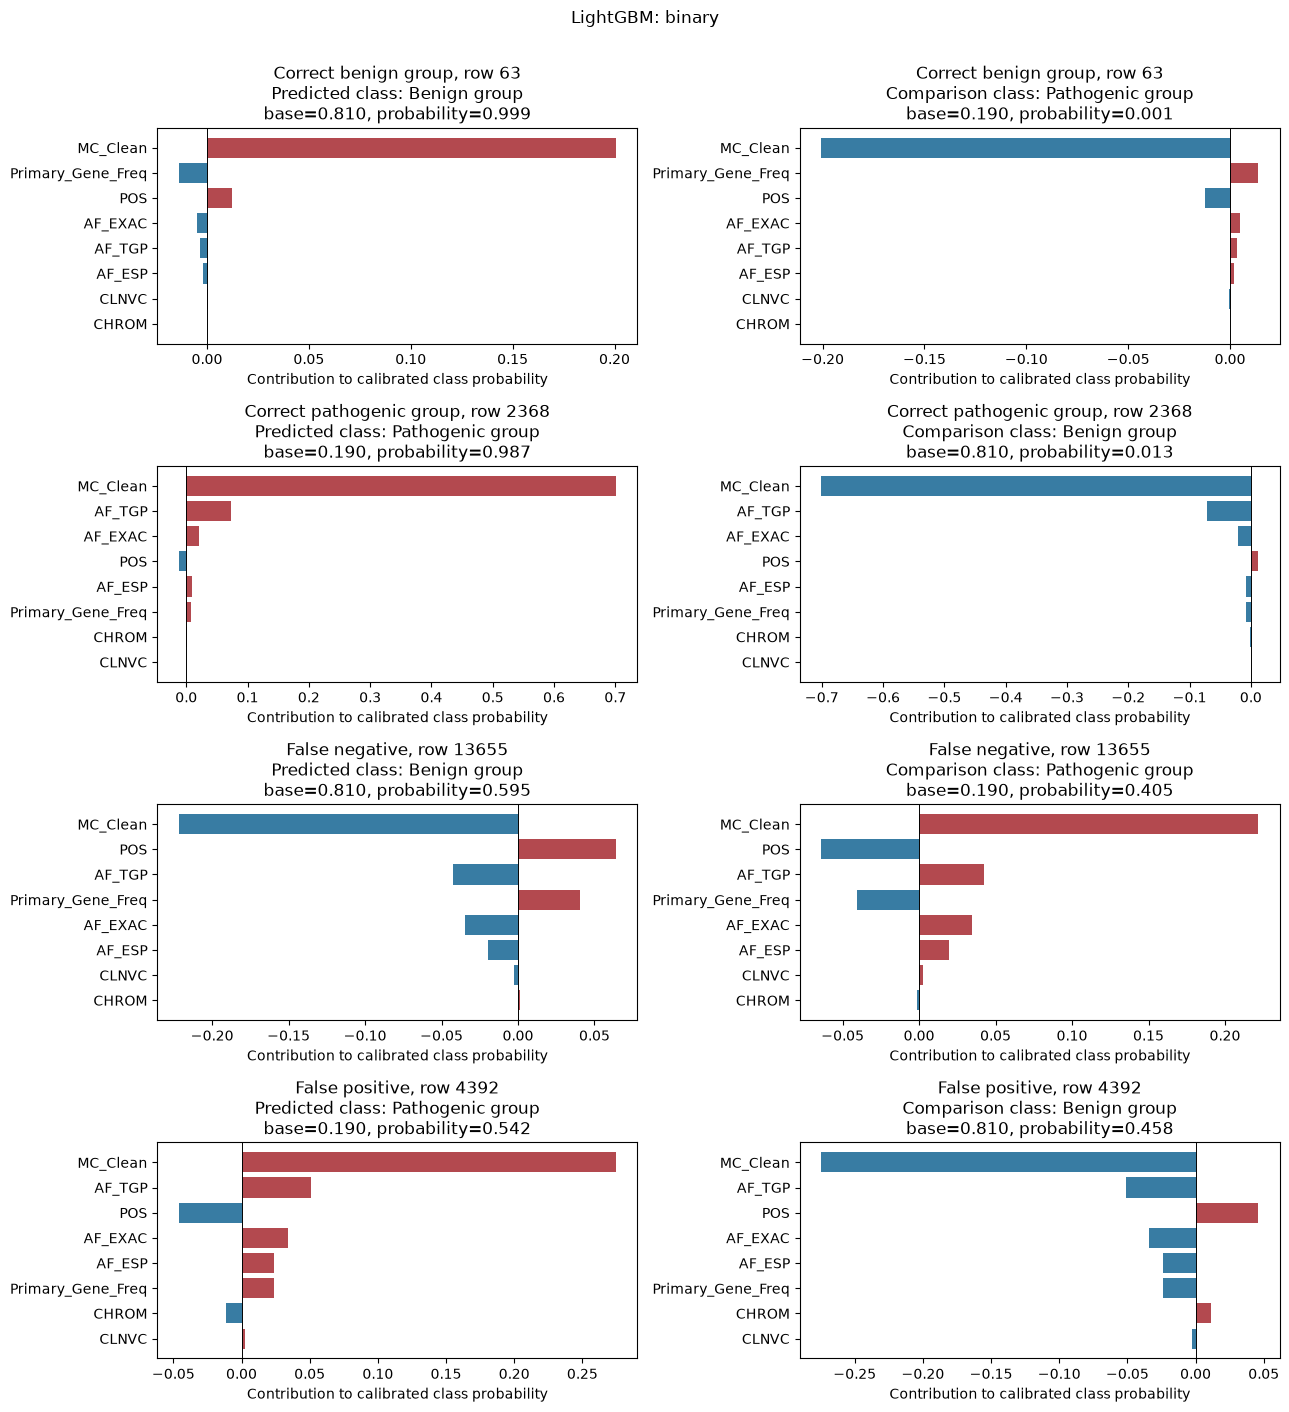

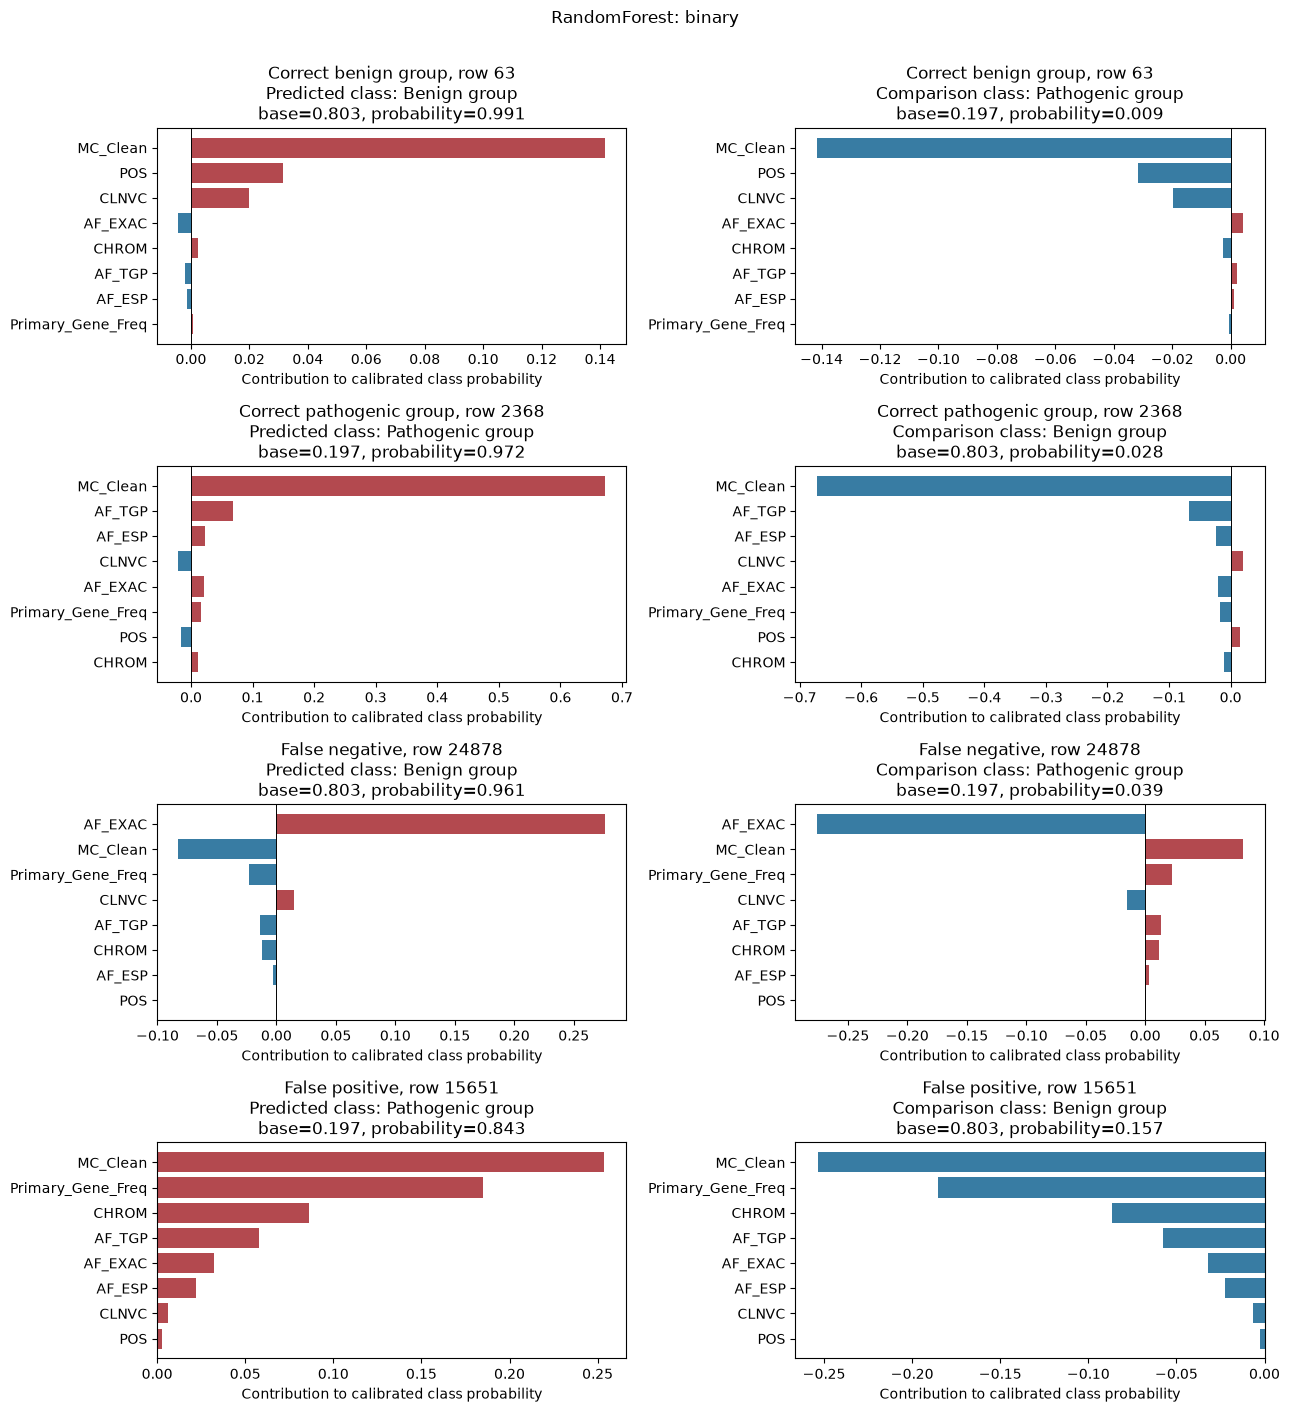

,model,task,category,row_index,true_label,predicted_label,predicted_probability,MC_Clean,CLNVC,primary_gene_metadata,max_additivity_error
0,XGBoost,four_class,Correct benign group,63,Likely_benign,Likely_benign,0.967979,synonymous_variant,single_nucleotide_variant,SAMD11,1.443290e-15
1,XGBoost,four_class,Correct pathogenic group,2368,Likely_pathogenic,Likely_pathogenic,0.630540,nonsense,single_nucleotide_variant,B3GALT6,3.330669e-16
2,XGBoost,four_class,False negative,24878,Likely_pathogenic,Likely_benign,0.484090,missense_variant,single_nucleotide_variant,ALPL,4.440892e-16
3,XGBoost,four_class,False positive,2924,Likely_benign,Likely_pathogenic,0.525724,missense_variant,single_nucleotide_variant,DVL1,2.220446e-16
4,LightGBM,binary,Correct benign group,63,Benign group,Benign group,0.999479,synonymous_variant,single_nucleotide_variant,SAMD11,1.443290e-15
5,LightGBM,binary,Correct pathogenic group,2368,Pathogenic group,Pathogenic group,0.987465,nonsense,single_nucleotide_variant,B3GALT6,6.661338e-16
6,LightGBM,binary,False negative,13655,Pathogenic group,Benign group,0.594849,missense_variant,single_nucleotide_variant,MTOR,3.885781e-16
7,LightGBM,binary,False positive,4392,Benign group,Pathogenic group,0.542087,missense_variant,single_nucleotide_variant,SKI,1.110223e-16
8,RandomForest,binary,Correct benign group,63,Benign group,Benign group,0.991264,synonymous_variant,single_nucleotide_variant,SAMD11,1.221245e-15
9,RandomForest,binary,Correct pathogenic group,2368,Pathogenic group,Pathogenic group,0.972468,nonsense,single_nucleotide_variant,B3GALT6,4.440892e-16


In [9]:
local_records, case_records = [], []
for (name, task), item in selected_models.items():
    pool_probability = probabilities(item, X[case_rows], task)
    actual = targets[task][case_rows]
    predicted = pool_probability.argmax(axis=1)
    chosen = choose_cases(actual, predicted, task)
    fig, axes = plt.subplots(len(chosen), 2, figsize=(13, 3.5 * len(chosen)), squeeze=False)
    for case_number, (category, position) in enumerate(chosen):
        row = int(case_rows[position])
        predict = lambda values: probabilities(item, values, task)
        phi, base, observed, residual = exact_group_shap(predict, X[row], background, groups)
        true_class, predicted_class = int(actual[position]), int(predicted[position])
        metadata = prepared['data'].iloc[row]
        case_records.append(dict(model=name, task=task, category=category, row_index=row,
                                 true_label=LABELS[task][true_class], predicted_label=LABELS[task][predicted_class],
                                 predicted_probability=float(observed[predicted_class]),
                                 MC_Clean=str(metadata['MC_Clean']), CLNVC=str(metadata['CLNVC']),
                                 primary_gene_metadata=str(metadata['Primary_Gene']),
                                 max_additivity_error=residual))
        for j, feature in enumerate(groups):
            for cls, label in enumerate(LABELS[task]):
                local_records.append(dict(model=name, task=task, category=category, row_index=row,
                                          feature=feature, output_class=label, shap_value=float(phi[j, cls]),
                                          background_probability=float(base[cls]), probability=float(observed[cls])))
        other_class = true_class if true_class != predicted_class else (2 if task == 'four_class' else 1) if true_class == 0 else 0
        for ax, cls, role in zip(axes[case_number], [predicted_class, other_class], ['Predicted class', 'Comparison class']):
            order = np.argsort(np.abs(phi[:, cls]))
            contributions = phi[order, cls]
            ax.barh(np.array(list(groups))[order], contributions,
                    color=np.where(contributions >= 0, '#b3494f', '#387ca3'))
            ax.axvline(0, color='black', linewidth=.7)
            ax.set_title(f'{category}, row {row}\n{role}: {LABELS[task][cls]}\n'
                         f'base={base[cls]:.3f}, probability={observed[cls]:.3f}')
            ax.set_xlabel('Contribution to calibrated class probability')
    fig.suptitle(f'{name}: {task}', y=1.005)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'{name}_{task}_local_cases.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
local_values = pd.DataFrame(local_records)
cases = pd.DataFrame(case_records)
local_values.to_csv(OUTPUT_DIR / 'local_grouped_shap_values.csv', index=False)
cases.to_csv(OUTPUT_DIR / 'local_cases.csv', index=False)
display(cases)

## 6. Interpretation and comparison

Fill in the report from the generated results. Describe the largest global score drops,
then connect local contributions to correct predictions, false negatives and false positives.
Compare binary LightGBM and Random Forest on the common rows and cases. Their selected
local cases can differ; a claim about the same variant requires matching `row_index`.
Do not infer a universal frequency cutoff from importance rankings. Gene frequency is
a training-dataset count proxy, not expression or a direct biological gene-importance score.
Gene names in case tables are descriptive metadata, not directly encoded gene identities.

The four-class XGBoost interpretation should distinguish cross-group mistakes from
confusion between adjacent confidence labels. Its score is not comparable to a binary score.
Missing frequency values were filled with zero upstream; the model does not distinguish
missing frequency from observed zero frequency. Background-dependent contributions and
model reliance do not establish biological causation or clinical validity.

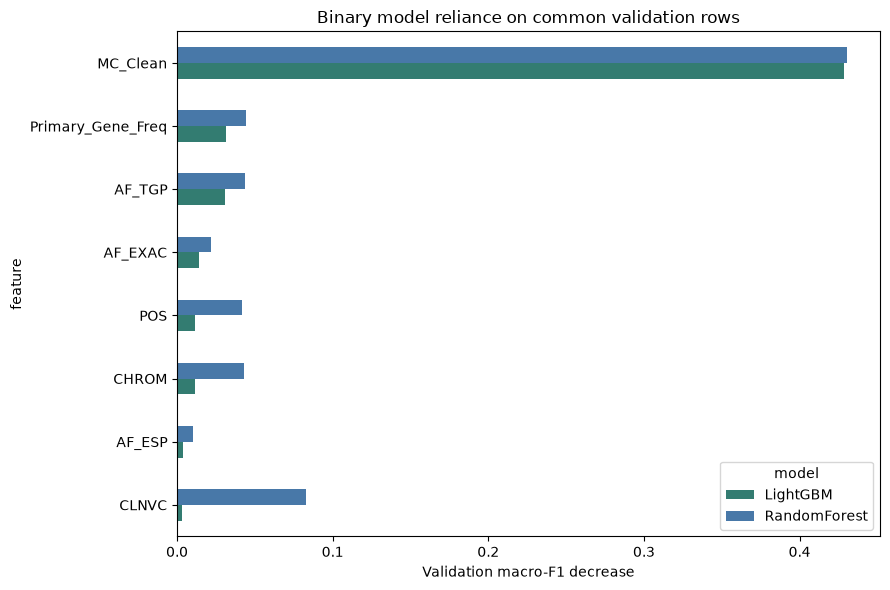

Analysis outputs saved to: tree_interpretability_results


In [10]:
binary = importance.loc[importance['task'] == 'binary']
comparison = binary.pivot(index='feature', columns='model', values='mean_macro_f1_drop')
comparison.to_csv(OUTPUT_DIR / 'binary_importance_comparison.csv')
ax = comparison.sort_values('LightGBM').plot.barh(figsize=(9, 6), color=['#337c71', '#4878a8'])
ax.set(xlabel='Validation macro-F1 decrease', title='Binary model reliance on common validation rows')
ax.figure.tight_layout()
ax.figure.savefig(OUTPUT_DIR / 'binary_importance_comparison.png', dpi=180)
plt.show()
plt.close(ax.figure)
record = dict(upstream_commit='bdb51d3b6fa87fc6688586e16917feb995f4addb',
              source_sha256=prepared['source_sha256'], environment=environment,
              explained_output='sigmoid-calibrated class probability',
              global_partition='validation', global_rows=len(global_rows), repeats=PERMUTATION_REPEATS,
              case_partition='test', case_pool_rows=len(case_rows), background_partition='train',
              background_rows=len(background_rows), seed=SEED,
              local_method='exact grouped empirical interventional Shapley; 256 coalitions',
              model_checks=model_checks.to_dict(orient='records'),
              max_additivity_error=float(cases['max_additivity_error'].max()))
(OUTPUT_DIR / 'analysis_record.json').write_text(json.dumps(record, indent=2), encoding='utf-8')
print('Analysis outputs saved to:', OUTPUT_DIR.resolve())

## References

- Group implementation: https://github.com/LakshyaMalik/Pathegenicity_Classification/blob/bdb51d3b6fa87fc6688586e16917feb995f4addb/hao_models.ipynb
- Permutation importance: https://scikit-learn.org/stable/modules/permutation_importance.html
- Shapley explanation framework: https://arxiv.org/abs/1705.07874
- Exact explanation: https://shap.readthedocs.io/en/latest/generated/shap.ExactExplainer.html

## Findings from the completed analysis

The full English interpretation and limitations are saved in `tree_interpretability_results/interpretability_summary.md`.

- On the 6,000-record validation sample, `MC_Clean` was the dominant group for all three models: macro-F1 decreases were 0.3201 for four-class XGBoost, 0.4285 for binary LightGBM and 0.4302 for binary Random Forest. These are absolute differences, not percentages, and task-specific magnitudes are not directly comparable.
- `AF_TGP` was the second-largest group for four-class XGBoost (0.1328). Binary Random Forest relied more on `CLNVC` (0.0827) than binary LightGBM (0.0034) on the common validation sample.
- Twelve local examples cover correct predictions, false negatives and false positives. Random Forest's false negative at row 24878 had benign probability 0.9605, illustrating that a high predicted probability can accompany an error.
- XGBoost and Random Forest were independently refitted. All three models matched the first 2,000 cached validation probabilities within 2.98e-8. Local attribution reconstruction error was below 1.45e-15.
- These results explain fitted-model behavior under the stated samples and background. They do not demonstrate biological causality or an improvement in model performance.
